# Function 5 - Week 4: observation review

Review what the completed experiments have shown before using a model to choose
the next query. This notebook examines measured inputs and outputs; fitted
relationships, predictive uncertainty and candidate selection belong in
[model review and next query](model_predictions.ipynb).

The independent Week 4 `observations.csv` contains **20 initial observations
and three returned queries**, including the Week 3 return received on
**14 October 2026**. Larger signed outputs are better. The four input settings
each lie in `[0, 1)`. Earlier weekly notebooks remain the record of the evidence
and reasoning available at those times.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_5/Week_04 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The three later rounds
each contain one deliberately selected query.

In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 5.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 20, 1: 1, 2: 1, 3: 1}:
    raise ValueError("This review expects the fixed Week 4 snapshot through round 3.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 4"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,4
1,Initial observations,20
2,Returned queries,3
3,Total observations,23
4,"Queries available, including Week 4",10


Weekly queries used: 3/13


## 2. Place the latest return among the observed outputs

The latest output is **8525.753289**, ranked **2/23 (1 = highest output)**.
It does not improve the incumbent of **8662.405001** from round 2. All three
returned queries exceed the initial best and are the three highest observations.

In [3]:
print(output_review["report"])

Latest recorded submission: round 3 (1 new output).
Compared with 22 earlier observations (23 outputs in total).
Earlier output range: [0.112939795371, 8662.40500125].

round-03: y = 8525.75328943 (positive); rank 2/23 (1 = highest output).
Inputs: x1 = 0.996065, x2 = 0.996814, x3 = 0.999999, x4 = 0.999999
Within the earlier output range.


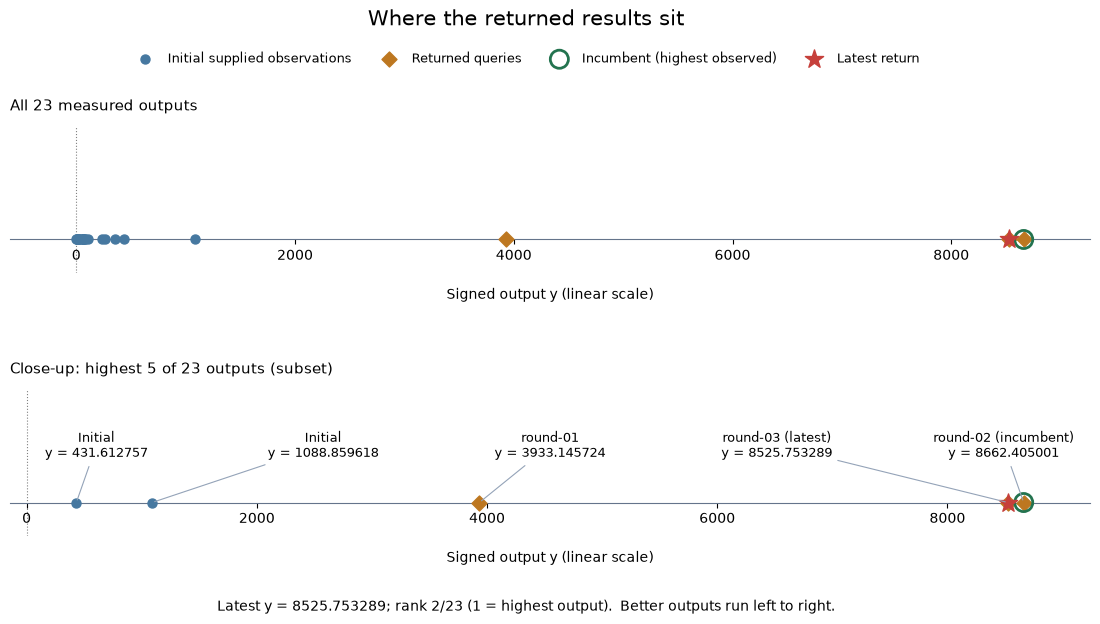

In [4]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 23 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. The later queries were
chosen using earlier evidence, so this view does not estimate the distribution
of scores throughout the input domain or establish the unknown global maximum.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in the
function's original output units.

In [5]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,1088.859618,—
Round 1,3933.145724,3933.145724,2844.286106
Round 2,8662.405001,8662.405001,4729.259277
Round 3,8525.753289,8662.405001,-136.651712


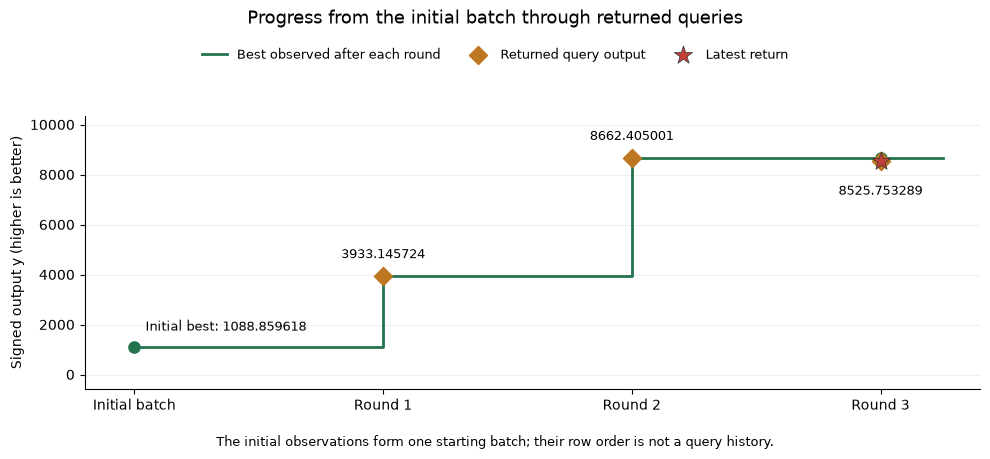

In [6]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

Rounds 1 and 2 each improved the incumbent; round 3 did not. All three
returns exceed the initial best of **1088.859618**. The best observed score
has improved by **7573.545383 output units** since the initial batch.

Round 3 remains a strong result despite returning **136.651712 output units**
below the previous best. Three selected queries do not establish the superiority
of the selection method, and one non-improvement does not establish a plateau.
There is no counterfactual showing what another query sequence would have returned.

## 4. Examine the strongest input combinations

Keep all four coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [7]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,y
observation_id,,,,,,,
round-02,1,2,0.999999,0.999999,0.999999,0.999999,8662.405001
round-03,2,3,0.996065,0.996814,0.999999,0.999999,8525.753289
round-01,3,1,0.375048,0.953644,0.999999,0.999999,3933.145724
initial-016,4,0,0.224189,0.846480,0.879484,0.878516,1088.859618
initial-019,5,0,0.119879,0.862540,0.643331,0.849804,431.612757


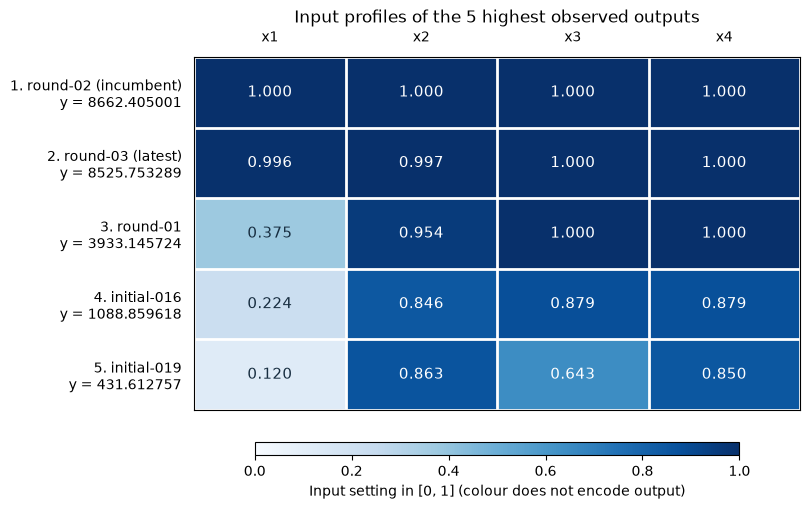

In [8]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

The three returned queries have **x3 = x4 = 0.999999** and exceed every
initial output. Rounds 2 and 3 also place x1 and x2 close to their upper limits;
they are the two strongest measured combinations. The gap to the third-best
output is substantial: the five rows are ordered by performance, not equally good.

These observations support examining this boundary region in model review.
They do not isolate any input's effect: other settings changed between queries,
and the initial sample contains different combinations. No monotonic relationship
or global maximum has been established.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [9]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full four-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.999999,0.996065,-0.003934
x2,0.999999,0.996814,-0.003185
x3,0.999999,0.999999,0.000000
x4,0.999999,0.999999,0.000000


Previous best: round-02; y = 8662.405001
Full four-input distance to previous best: 0.005062
Latest output minus previous best: -136.651712
Nearest earlier observation: round-02 (distance 0.005062)
Repeated full input combinations: 0


Round 2 is both the previous best and the nearest earlier observation to round 3.
Their full four-input distance is **0.005062**. Only x1 and x2 changed; x3 and
x4 stayed at **0.999999**. The latest output is **136.651712 lower**.

This is another high output at a nearby combination, rather than a new incumbent.
Two nearby measurements do not establish a local maximum or measure repeat-evaluation
noise. Neither input change can be assigned the output difference independently.

## 5. Carry the evidence into model review

The strongest returns keep the upper-boundary region worth examining, with
round 3 adding a nearby high measurement without improving the incumbent.
The large gain from the initial batch and the smaller latest setback should
both remain visible when reviewing the next proposal.

Continue in [model review and next query](model_predictions.ipynb) to examine:

- whether held-out GP predictions remain useful against the mean baseline,
  including their errors at the strongest observations;
- how predicted performance and uncertainty contribute to the next candidate;
- how predictions at the proposed location change under the tested noise
  assumptions, and whether exploration weights change the selected candidate,
  with ten query opportunities remaining.

The companion contains a saved Week 4 model run and an unconfirmed proposal.
Its validation and candidate comparisons use models, so they remain there.
No Week 4 submission is recorded here.

**Historical forecast check:** the [saved Week 3 model run](../Week_03/model_predictions.ipynb)
predicted **8555.632022** for the submitted input. The measured return was
**8525.753289**, or **29.878733 lower**. The saved forecast is
rounded to six decimals. This is a prediction made before the return, not a
model refitted with its answer; one forecast error does not establish calibration.